# Group XX - Machine Learning, Element 1: Apply dataset preparation mechanisms
| Item | Details |
|---|---|
| Group | **Group XX** |
| Members | **IGIHOZO Bienvenue** and **MUGISHA Aime Patrick** |
| Question | **Q1 - Predicting maize yield for farmer cooperatives in Rwanda (MCSU)** |
| Stage | **3 - Explore and audit the data (EDA)** |
| Driver / Navigator | Driver: IGIHOZO Bienvenue / Navigator: MUGISHA Aime Patrick |


## Stage 3 - Explore and audit the data (EDA) (PC 1.3)
**Goal:** understand the data and find every quality problem **before changing anything**. Each check is shown, also when
it finds nothing, so the reader can see it was done.

In [1]:
import sys  # lets us tell Python where our own code (src/) is
from pathlib import Path  # file paths that work on every computer
import warnings  # hide harmless library notices
warnings.filterwarnings("ignore")  # keep the output readable
import numpy as np  # maths on whole columns
import pandas as pd  # the DataFrame table
ROOT = Path.cwd().parent  # notebooks/ is inside q1_maize_yield
sys.path.insert(0, str(ROOT / "src"))  # make src/maize_pipeline.py importable
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)  # show every column
RAW = ROOT / "data" / "raw" / "maize_yield_rwanda_rw.csv"  # the original file (never edited)
import maize_pipeline as mp  # our reusable functions

import matplotlib.pyplot as plt  # charts
import seaborn as sns  # statistical charts
sns.set_theme(style="whitegrid")  # chart style
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)  # chart folder
raw = pd.read_csv(RAW)  # original file
num_cols = raw.select_dtypes("number").columns.drop("year").tolist()  # numeric measures
cat_cols = ["season", "province", "district", "soil_type", "seed_variety", "farming_practice", "irrigation"]  # categories
print(raw.shape)  # size

(1426, 20)


### 3.1 Describe the dataset

In [2]:
raw.describe().T.round(2)  # count, mean, std, min, quartiles, max

,count,mean,std,min,25%,50%,75%,max
year,1426.0,2019.51,2.86,2015.00,2017.00,2020.00,2022.00,2024.00
altitude_m,1426.0,1704.32,221.27,1243.00,1507.00,1702.50,1879.75,2341.00
rainfall_mm,1415.0,516.17,155.68,150.00,419.35,530.60,627.45,933.30
avg_temp_c,1426.0,19.40,1.65,15.40,18.02,19.40,20.70,23.00
soil_ph,1412.0,5.84,0.44,4.50,5.53,5.84,6.13,7.20
npk_kg_ha,1426.0,66.99,47.31,0.00,26.30,62.45,104.98,208.10
urea_kg_ha,1426.0,38.77,31.57,0.00,11.50,33.10,61.88,135.20
manure_t_ha,1426.0,2.08,1.36,0.00,1.06,2.00,3.03,6.86
plant_density_per_ha,1426.0,46322.31,9695.82,19337.00,38471.50,46901.00,53806.25,72248.00
farm_area_ha,1426.0,0.80,0.51,0.10,0.46,0.67,0.98,4.22


In [3]:
for c in cat_cols:  # every category column
    print(f"{c}: {raw[c].nunique()} labels ->", raw[c].value_counts().to_dict() if raw[c].nunique() < 10 else sorted(raw[c].unique()))  # labels

season: 3 labels -> {'A': 600, 'B': 600, 'C': 226}
province: 5 labels -> {'Southern': 388, 'Western': 348, 'Eastern': 328, 'Northern': 230, 'Kigali': 132}
district: 30 labels -> ['Bugesera', 'Burera', 'Gakenke', 'Gasabo', 'Gatsibo', 'Gicumbi', 'Gisagara', 'Huye', 'Kamonyi', 'Karongi', 'Kayonza', 'Kicukiro', 'Kirehe', 'Muhanga', 'Musanze', 'Ngoma', 'Ngororero', 'Nyabihu', 'Nyagatare', 'Nyamagabe', 'Nyamasheke', 'Nyanza', 'Nyarugenge', 'Nyaruguru', 'Rubavu', 'Ruhango', 'Rulindo', 'Rusizi', 'Rutsiro', 'Rwamagana']
soil_type: 5 labels -> {'Loam': 410, 'Clay loam': 276, 'Clay': 273, 'Sandy loam': 261, 'Volcanic': 206}
seed_variety: 6 labels -> {'ZM621': 297, 'Local': 281, 'ZM607': 256, 'RHM104': 216, 'WH505': 216, 'PAN691': 160}
farming_practice: 2 labels -> {'Improved': 783, 'Traditional': 643}
irrigation: 2 labels -> {'No': 1298, 'Yes': 128}


**Reading the summary:** all minimums and maximums are realistic (pH 4.5-7.2, temperature 15.4-23 C, altitude 1,243-2,341 m,
yield 1.0-5.2 t/ha). Labels are consistent (one spelling each). `farm_area_ha` has a long right tail (max 4.2 ha vs median 0.67).
The province is written **"Kigali"** instead of the official **"Kigali City"**.

### 3.2 Missing values and duplicates

In [4]:
missing = raw.isna().sum()  # empty cells per column
miss_tbl = pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(2)})[missing > 0]  # only columns with gaps
print("Exact duplicate rows                 :", raw.duplicated().sum())  # identical rows
print("Duplicate record_id                  :", raw["record_id"].duplicated().sum())  # repeated code
print("Same content under another record_id :", raw.drop(columns="record_id").duplicated().sum())  # copied forms
print("Rows by number of gaps               :", raw.isna().sum(axis=1).value_counts().sort_index().to_dict())  # gaps per row
miss_tbl  # table

Exact duplicate rows                 : 0
Duplicate record_id                  : 0
Same content under another record_id : 0
Rows by number of gaps               : {0: 1412, 2: 3, 3: 11}


,missing,percent
rainfall_mm,11,0.77
soil_ph,14,0.98
pest_incidence_index,14,0.98


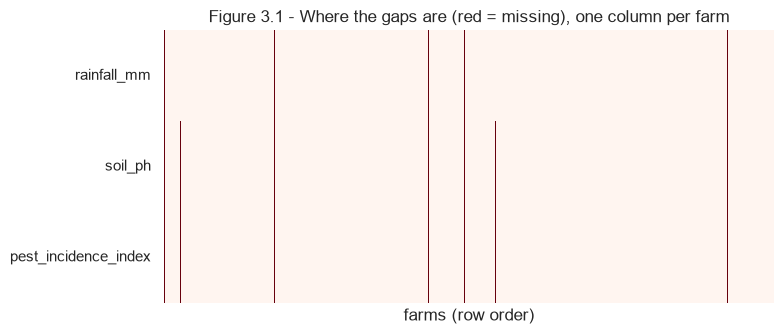

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))  # chart
sns.heatmap(raw[["rainfall_mm", "soil_ph", "pest_incidence_index"]].isna().T, cbar=False, cmap="Reds", ax=ax, xticklabels=False)  # red = missing
ax.set_title("Figure 3.1 - Where the gaps are (red = missing), one column per farm"); ax.set_xlabel("farms (row order)")  # labels
plt.tight_layout(); plt.savefig(FIG / "fig3_1_missing.png", dpi=120); plt.show()  # save and display

**Interpretation:** only 39 cells are empty (under 1 % per column), but they are **not random**: 11 farms miss all three
values and 3 farms miss two - the same farms had no soil test, no pest scouting and no rain record. We keep these farms,
impute the values (learned on the training set) and test an indicator `field_data_missing` in Stage 5. No duplicates were found.

### 3.3 Consistency checks

In [6]:
official = raw["district"].map(mp.DISTRICT_PROVINCE)  # official province of each district
print("Districts:", raw["district"].nunique(), "| not in official list:", (~raw["district"].isin(mp.DISTRICT_PROVINCE)).sum())  # 30 expected
print("Province does not match district (ignoring 'Kigali' name):", (official != raw["province"].replace({"Kigali": "Kigali City"})).sum())  # mapping check
print("Rows with 'Kigali' instead of 'Kigali City':", (raw["province"] == "Kigali").sum())  # naming
for c, allowed in mp.ALLOWED.items():  # allowed labels
    print(f"{c:<17} labels outside allowed list: {(~raw[c].isin(allowed)).sum()}")  # 0 expected
print("\nRecords per season:", raw["season"].value_counts().to_dict())  # balance
pd.crosstab(raw["season"], raw["irrigation"], margins=True)  # irrigation by season

Districts: 30 | not in official list: 0
Province does not match district (ignoring 'Kigali' name): 0
Rows with 'Kigali' instead of 'Kigali City': 132
season            labels outside allowed list: 0
soil_type         labels outside allowed list: 0
seed_variety      labels outside allowed list: 0
farming_practice  labels outside allowed list: 0
irrigation        labels outside allowed list: 0

Records per season: {'A': 600, 'B': 600, 'C': 226}


irrigation,No,Yes,All
season,,,
A,568,32,600
B,566,34,600
C,164,62,226
All,1298,128,1426


**Finding:** labels and the district-province mapping are correct. Season C has far fewer records (226 vs 600) and only 128
farms are irrigated - mostly in Season C, as the agronomist expects, but also 66 in Seasons A and B (plausible for marshland
plots, kept). These small groups make results for Season C and irrigation less certain.

### 3.4 Outliers (box plots + IQR rule) and realistic ranges

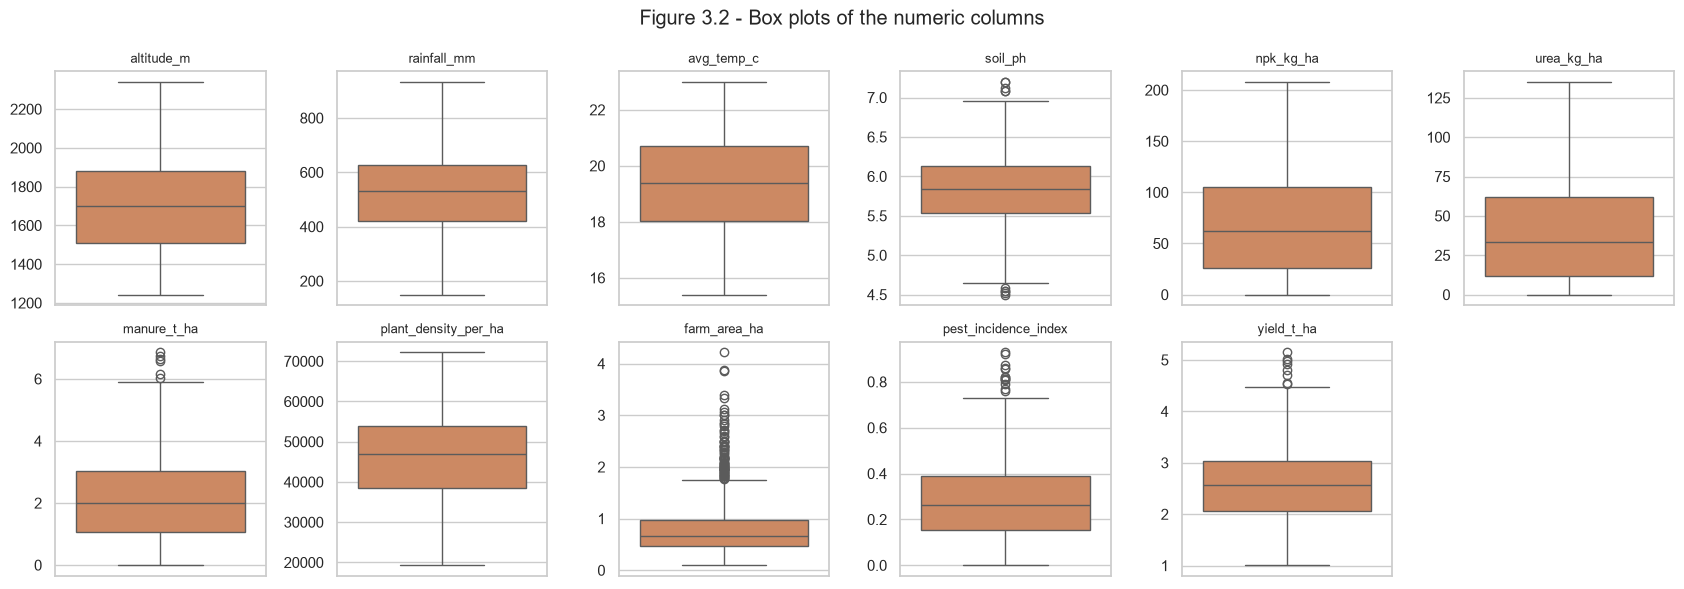

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(17, 6)); axes = axes.ravel()  # 11 small charts
for ax, c in zip(axes, num_cols):  # one box per numeric column
    sns.boxplot(y=raw[c], ax=ax, color="#DD8452"); ax.set_title(c, fontsize=9); ax.set_ylabel("")  # box plot
axes[-1].axis("off")  # 12th panel unused
fig.suptitle("Figure 3.2 - Box plots of the numeric columns"); plt.tight_layout()  # title
plt.savefig(FIG / "fig3_2_boxplots.png", dpi=120); plt.show()  # save and display

In [8]:
def iqr_report(s):  # IQR rule and agronomic range for one column
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1  # quartiles
    lo, hi = mp.RANGES[s.name]  # realistic range
    return pd.Series({"IQR_lower": q1 - 1.5 * i, "IQR_upper": q3 + 1.5 * i,
                      "IQR_outliers": int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()),
                      "outside_realistic_range": int((~s.between(lo, hi) & s.notna()).sum()),
                      "skew": s.skew()})  # result
raw[num_cols].apply(iqr_report).T.round(2)  # every numeric column

,IQR_lower,IQR_upper,IQR_outliers,outside_realistic_range,skew
altitude_m,947.88,2438.88,0.0,0.0,0.23
rainfall_mm,107.20,939.60,0.0,0.0,-0.33
avg_temp_c,14.01,24.71,0.0,0.0,-0.05
soil_ph,4.63,7.03,10.0,0.0,-0.01
npk_kg_ha,-91.71,222.99,0.0,0.0,0.31
urea_kg_ha,-64.06,137.44,0.0,0.0,0.55
manure_t_ha,-1.89,5.98,6.0,0.0,0.36
plant_density_per_ha,15469.38,76808.38,0.0,0.0,-0.13
farm_area_ha,-0.32,1.76,75.0,0.0,1.95
pest_incidence_index,-0.20,0.75,13.0,0.0,0.74


**Interpretation:** the IQR rule flags some values (75 farm areas above ~1.8 ha, 13 high pest indices, 10 pH values, 8 yields,
6 manure values) but **none is outside a realistic range** - they are real large farms, heavy pest years and good harvests,
not typing errors. Decision: **keep them** (removing them would hide real risk); reduce the farm-area skew (1.95) with a log.

### 3.5 The target

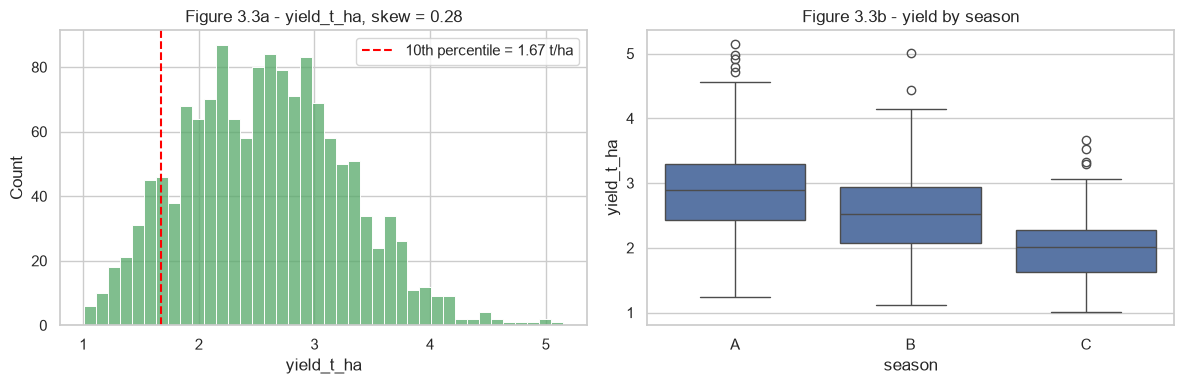

farms below 1.0 t/ha (agronomist 'very low'): 0


In [9]:
y = raw[mp.TARGET]  # target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # two charts
sns.histplot(y, bins=40, ax=axes[0], color="#55A868"); axes[0].set_title(f"Figure 3.3a - yield_t_ha, skew = {y.skew():.2f}")  # distribution
axes[0].axvline(y.quantile(.10), color="red", ls="--", label=f"10th percentile = {y.quantile(.10):.2f} t/ha"); axes[0].legend()  # low-yield line
sns.boxplot(data=raw, x="season", y=mp.TARGET, order=["A", "B", "C"], ax=axes[1]); axes[1].set_title("Figure 3.3b - yield by season")  # by season
plt.tight_layout(); plt.savefig(FIG / "fig3_3_target.png", dpi=120); plt.show()  # save and display
print("farms below 1.0 t/ha (agronomist 'very low'):", (y < 1.0).sum())  # none

**Interpretation:** yield is almost symmetric (skew 0.28) around 2.6 t/ha and stays within 1.0-5.2 t/ha. **No farm** is below
the agronomist's 1,000 kg/ha, so "very low harvest" (question E) is defined as the **bottom 10 % of the training farms**
(about 1.7 t/ha), computed after the split.

### 3.6 Relationships

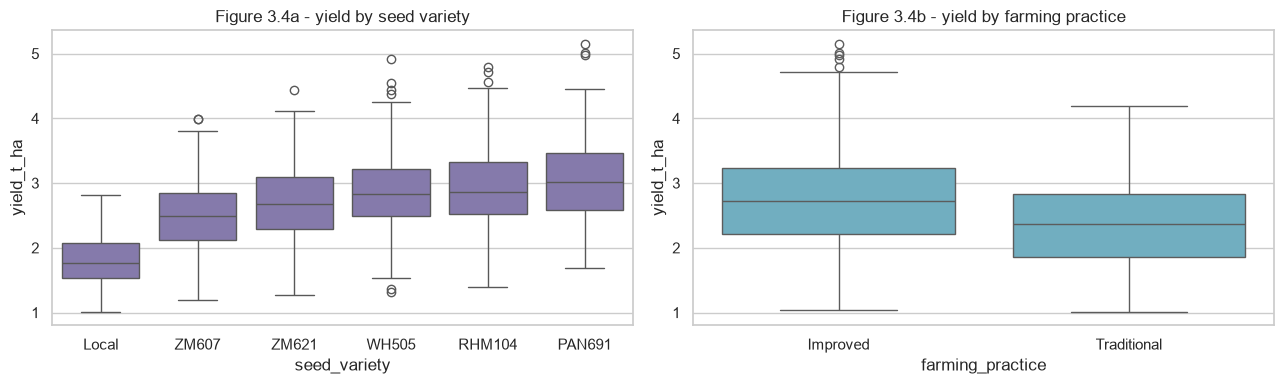

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # two charts
order = raw.groupby("seed_variety")[mp.TARGET].median().sort_values().index  # sort by median yield
sns.boxplot(data=raw, x="seed_variety", y=mp.TARGET, order=order, ax=axes[0], color="#8172B3")  # yield by seed
axes[0].set_title("Figure 3.4a - yield by seed variety")  # title
sns.boxplot(data=raw, x="farming_practice", y=mp.TARGET, ax=axes[1], color="#64B5CD")  # yield by practice
axes[1].set_title("Figure 3.4b - yield by farming practice")  # title
plt.tight_layout(); plt.savefig(FIG / "fig3_4_seed_practice.png", dpi=120); plt.show()  # save and display

**Interpretation:** Local seed gives clearly lower yields than all improved varieties; the hybrids (PAN691, RHM104, WH505) are
highest. Improved practice also yields more - question B can be answered.

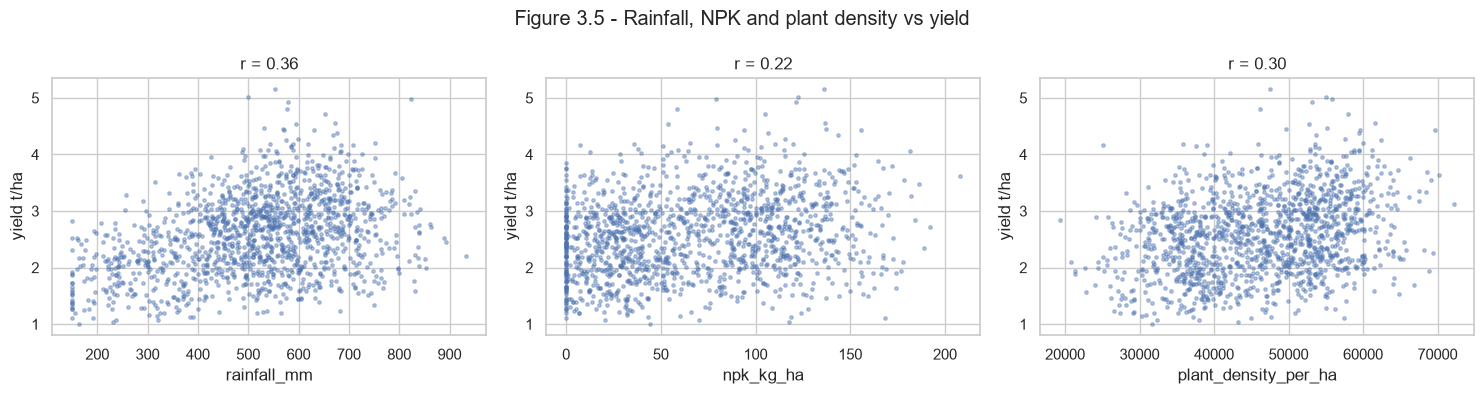

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # three scatter plots
for ax, c in zip(axes, ["rainfall_mm", "npk_kg_ha", "plant_density_per_ha"]):  # three drivers
    ax.scatter(raw[c], raw[mp.TARGET], s=6, alpha=.4)  # one dot per farm
    ax.set_xlabel(c); ax.set_ylabel("yield t/ha"); ax.set_title(f"r = {raw[c].corr(raw[mp.TARGET]):.2f}")  # correlation in title
fig.suptitle("Figure 3.5 - Rainfall, NPK and plant density vs yield"); plt.tight_layout()  # title
plt.savefig(FIG / "fig3_5_drivers.png", dpi=120); plt.show()  # save and display

**Interpretation:** rainfall (r about 0.36), plant density (0.30) and fertiliser (0.22) all raise yield, but with wide scatter:
yield depends on several factors together, which is why engineered combinations (nitrogen applied, input package) are useful.

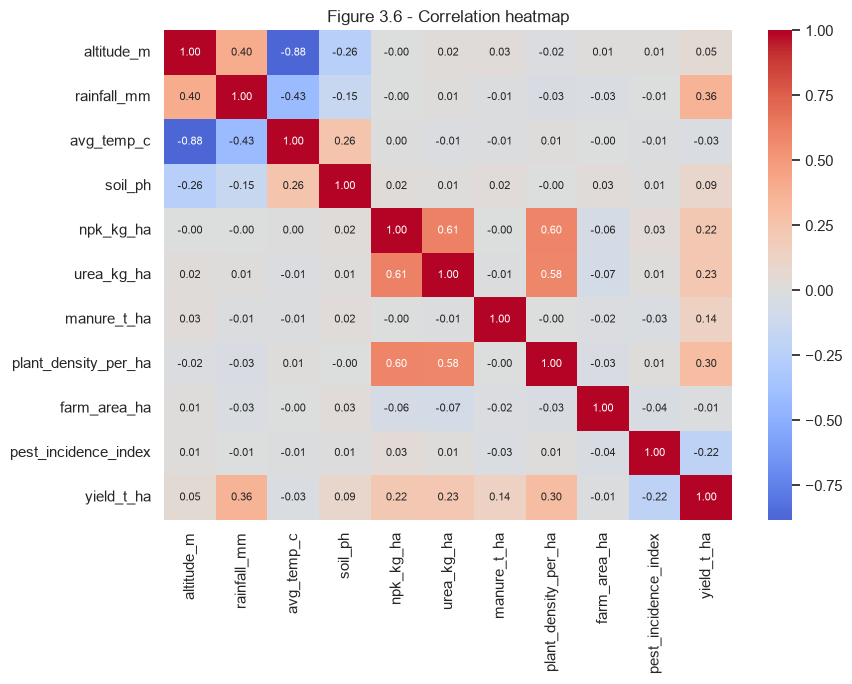

In [12]:
corr = raw[num_cols].corr()  # correlation matrix
fig, ax = plt.subplots(figsize=(9, 7))  # chart
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})  # heatmap
ax.set_title("Figure 3.6 - Correlation heatmap"); plt.tight_layout()  # title
plt.savefig(FIG / "fig3_6_corr.png", dpi=120); plt.show()  # save and display

**Interpretation:** altitude and temperature are strongly linked (r = -0.88: highlands are cooler), so they carry overlapping
information. **No column is suspiciously close to the target** (no hidden post-harvest variable). **Timing note (question E):**
`rainfall_mm` and `avg_temp_c` are **season totals/averages**, fully known only at the end of the season, close to harvest;
`pest_incidence_index` is observed during the season. For an *early* warning the modelling team must use rainfall-to-date
instead. We keep the columns (needed for A-D) and document this risk.

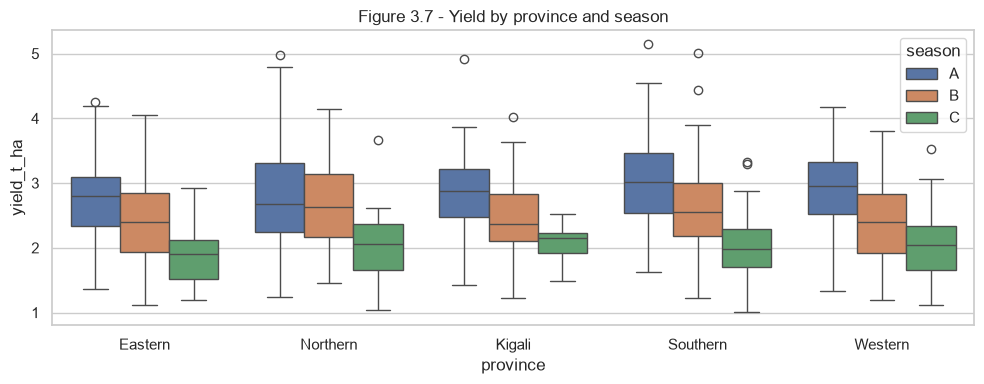

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))  # chart
sns.boxplot(data=raw, x="province", y=mp.TARGET, hue="season", hue_order=["A", "B", "C"], ax=ax)  # province x season
ax.set_title("Figure 3.7 - Yield by province and season"); plt.tight_layout()  # title
plt.savefig(FIG / "fig3_7_province_season.png", dpi=120); plt.show()  # save and display

**Interpretation:** differences between provinces and seasons are visible - question D can be answered.

### 3.7 Data Quality Report - saved to `docs/data_quality_report.csv`

In [14]:
iqr = raw[num_cols].apply(iqr_report).T  # outlier summary from above
dqr = pd.DataFrame([  # problem, columns, records, severity, treatment
    (1, "Missing values that occur together (no soil test / scouting / rain record)", "rainfall_mm, soil_ph, pest_incidence_index",
     int(raw[["rainfall_mm", "soil_ph", "pest_incidence_index"]].isna().any(axis=1).sum()), "Medium",
     "keep rows; median imputation fitted on train; indicator tested in Stage 5"),
    (2, "IQR outliers (all within realistic ranges)", ", ".join(iqr.index[iqr.IQR_outliers > 0]), int(iqr.IQR_outliers.sum()), "Low",
     "keep (real farms); log transform for farm area"),
    (3, "Right-skewed farm area (skew 1.95)", "farm_area_ha", len(raw), "Low", "log(1 + area) feature"),
    (4, "True zeros in fertiliser/manure (no input used) - must not be read as missing", "npk_kg_ha, urea_kg_ha, manure_t_ha",
     int((raw[["npk_kg_ha", "urea_kg_ha", "manure_t_ha"]] == 0).any(axis=1).sum()), "Medium", "keep 0; add uses_mineral_fertiliser flag"),
    (5, "Strongly related columns (altitude vs temperature r = -0.88; NPK/urea vs nitrogen)", "altitude_m, avg_temp_c, urea_kg_ha",
     len(raw), "Low", "keep altitude + temperature deviation; drop urea after creating nitrogen feature"),
    (6, "Unbalanced groups: Season C (226 rows), irrigated farms (128)", "season, irrigation", 226, "Medium",
     "stratified split by season; report lower certainty"),
    (7, "Non-official province name 'Kigali'", "province", int((raw["province"] == "Kigali").sum()), "Low", "rename to 'Kigali City'"),
    (8, "Target unit t/ha while the brief and agronomist use kg/ha", "yield_t_ha", len(raw), "Low", "keep t/ha and add yield_kg_ha"),
    (9, "No farm below 1,000 kg/ha - agronomist threshold cannot define 'very low'", "yield_t_ha", 0, "Medium",
     "low_yield_risk = bottom 10 % of TRAINING yields"),
    (10, "Timing leakage risk: season rainfall/temperature known only at season end", "rainfall_mm, avg_temp_c, pest_incidence_index",
     len(raw), "High", "keep for A-D; warn modelling team to use data-to-date for early warning (E)"),
    (11, "Information missing vs brief: no farm/cooperative code, no planting date", "-", len(raw), "Medium",
     "cannot analyse per cooperative or planting date; recommend collecting"),
    (12, "Checks with nothing found: duplicates, wrong labels, wrong district-province, impossible values",
     "all", 0, "-", "documented checks; no change needed"),
], columns=["no", "problem", "columns", "records_affected", "severity", "proposed_treatment"])
dqr.to_csv(ROOT / "docs" / "data_quality_report.csv", index=False)  # save
dqr  # display

,no,problem,columns,records_affected,severity,proposed_treatment
0,1,Missing values that occur together (no soil te...,"rainfall_mm, soil_ph, pest_incidence_index",14,Medium,keep rows; median imputation fitted on train; ...
1,2,IQR outliers (all within realistic ranges),"soil_ph, manure_t_ha, farm_area_ha, pest_incid...",112,Low,keep (real farms); log transform for farm area
2,3,Right-skewed farm area (skew 1.95),farm_area_ha,1426,Low,log(1 + area) feature
3,4,True zeros in fertiliser/manure (no input used...,"npk_kg_ha, urea_kg_ha, manure_t_ha",351,Medium,keep 0; add uses_mineral_fertiliser flag
4,5,Strongly related columns (altitude vs temperat...,"altitude_m, avg_temp_c, urea_kg_ha",1426,Low,keep altitude + temperature deviation; drop ur...
5,6,"Unbalanced groups: Season C (226 rows), irriga...","season, irrigation",226,Medium,stratified split by season; report lower certa...
6,7,Non-official province name 'Kigali',province,132,Low,rename to 'Kigali City'
7,8,Target unit t/ha while the brief and agronomis...,yield_t_ha,1426,Low,keep t/ha and add yield_kg_ha
8,9,"No farm below 1,000 kg/ha - agronomist thresho...",yield_t_ha,0,Medium,low_yield_risk = bottom 10 % of TRAINING yields
9,10,Timing leakage risk: season rainfall/temperatu...,"rainfall_mm, avg_temp_c, pest_incidence_index",1426,High,keep for A-D; warn modelling team to use data-...


**Checkpoint answer - two problems and why they matter for the model**
1. **Missing values together in 14 farms:** if we simply deleted them we would lose farms that may differ (no soil test =
   less supported farmers); if we filled them using all rows we would leak test information. So: impute with training
   medians and add an indicator.
2. **Timing of rainfall/temperature:** a model trained on full-season rainfall looks good in testing but cannot be used
   for an early warning before the season ends - a form of leakage for question E.